# 🧬 REaLTabFormer: APT Data Augmentation Pipeline

## Advanced Synthetic Data Generation for Wazuh Security Logs

This notebook implements **REaLTabFormer** (Realistic Tabular Data Generation using Transformers) for generating high-quality synthetic APT (Advanced Persistent Threat) data from Wazuh SIEM logs.

### Why REaLTabFormer?
- ✅ **Native text handling** - No need to embed text columns like `rule.description`
- ✅ **Handles missing values** - Built-in support for sparse data
- ✅ **Preserves column relationships** - GPT-2 attention mechanism learns correlations
- ✅ **Full text reconstruction** - Generated data includes original text, not embeddings
- ✅ **Better quality** - Expected 80-90% acceptable features vs 0% with CTGAN

### Pipeline Overview:
1. **Data Loading** - Load Wazuh malicious alerts
2. **Smart Preprocessing** - Keep columns with >50% data, preserve text
3. **REaLTabFormer Training** - GPT-2 based tabular generation
4. **Synthetic Generation** - Generate 2x synthetic samples
5. **Quality Validation** - Statistical comparison with real data
6. **Visualization** - Distribution comparisons

---
**Author:** APT Augmentation Pipeline  
**Framework:** REaLTabFormer (GPT-2 based)  
**Data:** Wazuh SIEM Malicious Alerts

## SUPPRESS CUDA/TENSORFLOW WARNINGS

In [1]:
# ============================================================================
# 🔇 ULTIMATE WARNING SUPPRESSION - RUN THIS FIRST!
# ============================================================================
import os
import sys
import warnings

# ===== CRITICAL: Set these BEFORE any CUDA/TF imports =====
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
os.environ['CUDA_VISIBLE_DEVICES'] = os.environ.get('CUDA_VISIBLE_DEVICES', '0,1')

# Suppress CUDA/cuDNN/cuBLAS registration warnings
os.environ['TF_FORCE_GPU_ALLOW_GROWTH'] = 'true'
os.environ['TF_GPU_THREAD_MODE'] = 'gpu_private'

# Suppress gRPC and glog
os.environ['GRPC_VERBOSITY'] = 'ERROR'
os.environ['GRPC_TRACE'] = ''
os.environ['GLOG_minloglevel'] = '3'

# Suppress absl (TensorFlow's logging library)
os.environ['ABSL_MIN_LOG_LEVEL'] = '3'

# Suppress tokenizers parallelism warnings
os.environ['TOKENIZERS_PARALLELISM'] = 'false'

# Disable JAX if not needed
os.environ['JAX_PLATFORMS'] = ''

# Python-level warnings
warnings.filterwarnings('ignore')
warnings.filterwarnings('ignore', category=DeprecationWarning)
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

# Suppress Python warnings at the interpreter level
if not sys.warnoptions:
    warnings.simplefilter("ignore")

# Configure Python logging to ERROR only
import logging
logging.getLogger().setLevel(logging.ERROR)
logging.getLogger('absl').setLevel(logging.ERROR)
logging.getLogger('tensorflow').setLevel(logging.ERROR)
logging.getLogger('transformers').setLevel(logging.ERROR)

# ===== Now import TensorFlow/CUDA libraries =====
# This forces the imports to happen with all suppressions active
try:
    import tensorflow as tf
    tf.get_logger().setLevel('ERROR')
    tf.autograph.set_verbosity(0)
except ImportError:
    pass

print("✅ All warning suppressions activated")
print("   • CUDA/cuDNN/cuBLAS warnings suppressed")
print("   • TensorFlow logging disabled")
print("   • Python warnings filtered")

E0000 00:00:1768210236.971628      55 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1768210237.026996      55 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1768210237.468513      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1768210237.468556      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1768210237.468559      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1768210237.468562      55 computation_placer.cc:177] computation placer already registered. Please check linka

✅ All warning suppressions activated
   • CUDA/cuDNN/cuBLAS warnings suppressed
   • TensorFlow logging disabled
   • Python warnings filtered


## 📦 Section 1: Environment Setup & Installation

In [2]:
# ============================================================================
# 📦 INSTALL REQUIRED PACKAGES
# ============================================================================
# Run this cell first to install all dependencies

# Suppress CUDA/TensorFlow warnings (MUST be before any imports)
import os
os.environ["WANDB_DISABLED"] = "true"
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'  # Suppress TF logging
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'  # Disable oneDNN
os.environ['CUDA_VISIBLE_DEVICES'] = os.environ.get('CUDA_VISIBLE_DEVICES', '0')  # Ensure single GPU
os.environ['GRPC_VERBOSITY'] = 'ERROR'
os.environ['GLOG_minloglevel'] = '3'

# Suppress absl logging
import logging
logging.getLogger('absl').setLevel(logging.ERROR)

import subprocess
import sys
import warnings
warnings.filterwarnings('ignore')

def install_package(package):
    """Install package if not already installed"""
    try:
        __import__(package.split('[')[0].split('==')[0])
        print(f"✅ {package} already installed")
    except ImportError:
        print(f"📦 Installing {package}...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])
        print(f"✅ {package} installed successfully")

# Core packages
packages = [
    "realtabformer",        # Main library for tabular generation
    "pandas",
    "numpy",
    "matplotlib",
    "seaborn",
    "scikit-learn",
    "scipy",
    "tqdm",
    "plotly",
    "torch",                # PyTorch backend
    "transformers",# Hugging Face transformers 
    "openpyxl"
]

print("=" * 60)
print("🔧 INSTALLING DEPENDENCIES")
print("=" * 60)

for pkg in packages:
    install_package(pkg)

print("\n" + "=" * 60)
print("✅ ALL PACKAGES INSTALLED SUCCESSFULLY")
print("=" * 60)

🔧 INSTALLING DEPENDENCIES
📦 Installing realtabformer...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 kB 1.7 MB/s eta 0:00:00
✅ realtabformer installed successfully
✅ pandas already installed
✅ numpy already installed
✅ matplotlib already installed
✅ seaborn already installed
📦 Installing scikit-learn...
✅ scikit-learn installed successfully
✅ scipy already installed
✅ tqdm already installed
✅ plotly already installed
✅ torch already installed
✅ transformers already installed
✅ openpyxl already installed

✅ ALL PACKAGES INSTALLED SUCCESSFULLY


In [3]:
# ============================================================================
# 📚 IMPORT LIBRARIES
# ============================================================================
import os
import warnings
warnings.filterwarnings('ignore')


import json
import pickle
from datetime import datetime
from pathlib import Path

# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Machine Learning & Statistics
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score
from scipy import stats
from scipy.stats import ks_2samp, chi2_contingency

# Progress bars
from tqdm.auto import tqdm

# REaLTabFormer
from realtabformer import REaLTabFormer

# PyTorch
import torch

# Suppress warnings

# Set random seeds for reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

# Check GPU availability
device = "cuda" if torch.cuda.is_available() else "cpu"
print("=" * 60)
print("🖥️ SYSTEM INFORMATION")
print("=" * 60)
print(f"   • PyTorch version: {torch.__version__}")
print(f"   • Device: {device.upper()}")
if device == "cuda":
    print(f"   • GPU: {torch.cuda.get_device_name(0)}")
    print(f"   • GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
print(f"   • Random Seed: {RANDOM_SEED}")
print("=" * 60)

🖥️ SYSTEM INFORMATION
   • PyTorch version: 2.8.0+cu126
   • Device: CUDA
   • GPU: Tesla T4
   • GPU Memory: 15.83 GB
   • Random Seed: 42


In [5]:
# ============================================================================
# ⚙️ CONFIGURATION
# ============================================================================

from datetime import datetime
import os

PARENT_DIR = '/kaggle/input'
WORKING_PARENT_DIR = '/kaggle/working'

CONFIG = {
    'data_path': os.path.join(PARENT_DIR, 'maliciousaptdata/malicious_realtabformer.xlsx'),
    'output_dir': os.path.join(WORKING_PARENT_DIR, 'realtabformer_output'),
    'checkpoints_dir': os.path.join(WORKING_PARENT_DIR, 'realtabformer_checkpoints'),
    'backup_dir': os.path.join(WORKING_PARENT_DIR, 'final_model'),
    
    # REaLTabFormer parameters
    'model_type': 'tabular',
    'epochs': 150,
    'batch_size': 32,
    'train_size': 0.95,
    'gradient_accumulation_steps': 4,
    'logging_steps': 100,
    'save_steps': 500,
    'random_seed': 42,
    'experiment_id': f"apt_augmentation_{datetime.now().strftime('%Y%m%d_%H%M%S')}",
    
    # Generation parameters
    'synthetic_ratio': 2.0,
    'generation_batch_size': 256,
    
    # Quality thresholds
    'ks_threshold': 0.3,
    'l1_threshold': 0.3,
    
    # Device settings
    'device': 'cuda',
}

# ============================================================================
# 📋 PREDEFINED COLUMNS FOR REaLTabFormer
# ============================================================================

REALTABFORMER_COLUMNS = [
    'malicious',
    'cyber_kill_chain_tactic',
    'cyber_kill_chain_technique',
    '_source.rule.mitre.tactic',
    '_source.rule.mitre.technique',
    '_source.rule.mitre.id',
    '_source.rule.level',
    '_source.rule.groups',
    '_source.decoder.name',
    '_source.data.protocol',
    '_source.data.srcip',
    '_source.data.url',
]

AUDIT_INDICATOR_COLS = ['_source.data.audit.syscall', '_source.data.audit.exe', '_source.data.audit.command']
SYSCHECK_INDICATOR_COLS = ['_source.syscheck.event', '_source.syscheck.path']
SCA_INDICATOR_COLS = ['_source.data.sca.check.result', '_source.data.sca.failed']
NETWORK_INDICATOR_COLS = ['_source.data.protocol', '_source.data.srcip', '_source.data.url']

# Create directories
os.makedirs(CONFIG['output_dir'], exist_ok=True)
os.makedirs(CONFIG['checkpoints_dir'], exist_ok=True)
os.makedirs(CONFIG['backup_dir'], exist_ok=True)

print("=" * 70)
print("⚙️ CONFIGURATION")
print("=" * 70)
for key, value in CONFIG.items():
    print(f"   • {key}: {value}")
print(f"\n📋 Predefined columns: {len(REALTABFORMER_COLUMNS)} features")
print("=" * 70)

⚙️ CONFIGURATION
   • data_path: /kaggle/input/maliciousaptdata/malicious_realtabformer.xlsx
   • output_dir: /kaggle/working/realtabformer_output
   • checkpoints_dir: /kaggle/working/realtabformer_checkpoints
   • backup_dir: /kaggle/working/final_model
   • model_type: tabular
   • epochs: 150
   • batch_size: 32
   • train_size: 0.95
   • gradient_accumulation_steps: 4
   • logging_steps: 100
   • save_steps: 500
   • random_seed: 42
   • experiment_id: apt_augmentation_20260112_093459
   • synthetic_ratio: 2.0
   • generation_batch_size: 256
   • ks_threshold: 0.3
   • l1_threshold: 0.3
   • device: cuda

📋 Predefined columns: 12 features


## 📂 Section 2: Data Loading & Exploration

In [6]:
# ============================================================================
# 📂 LOAD RAW DATA
# ============================================================================

print("=" * 70)
print("📂 LOADING MALICIOUS DATA")
print("=" * 70)

# Try multiple possible paths
possible_paths = [
    CONFIG['data_path'],
    '/kaggle/input/apt-data/Malicious.csv',
    '/kaggle/input/malicious-data/Malicious.csv',
    'Malicious.csv',
    '../data/Malicious.csv',
    '/home/yacine/Desktop/PFE/Model/ML_models/months-data/Malicious.csv',
]

raw_data = None
for path in possible_paths:
    if os.path.exists(path):
        print(f"   📁 Found data at: {path}")
        if path.endswith('.xlsx'):
            raw_data = pd.read_excel(path, sheet_name='Sheet1')
        else:
            raw_data = pd.read_csv(path, low_memory=False)
        CONFIG['data_path'] = path
        break

if raw_data is None:
    raise FileNotFoundError(f"Could not find data file. Tried: {possible_paths}")

print(f"\n✅ Data loaded successfully!")
print(f"   • Shape: {raw_data.shape[0]:,} rows × {raw_data.shape[1]} columns")
print(f"   • Memory usage: {raw_data.memory_usage(deep=True).sum() / 1e6:.2f} MB")

# ============================================================================
# 🔧 CREATE BOOLEAN FLAGS FROM EXISTING DATA
# ============================================================================

print(f"\n🔧 CREATING BOOLEAN FLAGS:")

# Check which indicator columns exist
def check_any_not_null(df, cols):
    """Check if any of the columns has non-null values for each row"""
    existing_cols = [c for c in cols if c in df.columns]
    if not existing_cols:
        return pd.Series([False] * len(df), index=df.index)
    return df[existing_cols].notna().any(axis=1)

# Create boolean flags
raw_data['has_audit'] = check_any_not_null(raw_data, AUDIT_INDICATOR_COLS)
raw_data['has_syscheck'] = check_any_not_null(raw_data, SYSCHECK_INDICATOR_COLS)
raw_data['has_sca'] = check_any_not_null(raw_data, SCA_INDICATOR_COLS)
raw_data['has_network'] = check_any_not_null(raw_data, NETWORK_INDICATOR_COLS)

print(f"   • has_audit:   {raw_data['has_audit'].sum():,} rows ({raw_data['has_audit'].mean()*100:.1f}%)")
print(f"   • has_syscheck: {raw_data['has_syscheck'].sum():,} rows ({raw_data['has_syscheck'].mean()*100:.1f}%)")
print(f"   • has_sca:     {raw_data['has_sca'].sum():,} rows ({raw_data['has_sca'].mean()*100:.1f}%)")
print(f"   • has_network: {raw_data['has_network'].sum():,} rows ({raw_data['has_network'].mean()*100:.1f}%)")

# Add boolean flags to the column list
FINAL_COLUMNS = REALTABFORMER_COLUMNS + ['has_audit', 'has_syscheck', 'has_sca', 'has_network']

# ============================================================================
# 📋 SELECT COLUMNS
# ============================================================================

# Filter to keep only predefined columns that exist in the data
existing_columns = [col for col in FINAL_COLUMNS if col in raw_data.columns]
missing_columns = [col for col in FINAL_COLUMNS if col not in raw_data.columns]

print(f"\n📋 COLUMN SELECTION:")
print(f"   • Requested columns: {len(FINAL_COLUMNS)}")
print(f"   • Found in data: {len(existing_columns)}")
print(f"   • Missing: {len(missing_columns)}")

if missing_columns:
    print(f"\n⚠️ Missing columns:")
    for col in missing_columns:
        print(f"      - {col}")

# Select only the predefined columns
df = raw_data[existing_columns].copy()

print(f"\n✅ Working with {len(existing_columns)} columns:")
for col in existing_columns:
    pct = df[col].notna().sum() / len(df) * 100
    status = "✅" if pct >= 50 else "⚠️"
    print(f"   {status} {col}: {pct:.1f}%")

print("=" * 70)

📂 LOADING MALICIOUS DATA
   📁 Found data at: /kaggle/input/maliciousaptdata/malicious_realtabformer.xlsx

✅ Data loaded successfully!
   • Shape: 25,418 rows × 33 columns
   • Memory usage: 38.26 MB

🔧 CREATING BOOLEAN FLAGS:
   • has_audit:   3,246 rows (12.8%)
   • has_syscheck: 3,683 rows (14.5%)
   • has_sca:     3,061 rows (12.0%)
   • has_network: 22,043 rows (86.7%)

📋 COLUMN SELECTION:
   • Requested columns: 16
   • Found in data: 16
   • Missing: 0

✅ Working with 16 columns:
   ✅ malicious: 100.0%
   ✅ cyber_kill_chain_tactic: 96.6%
   ✅ cyber_kill_chain_technique: 96.1%
   ✅ _source.rule.mitre.tactic: 99.9%
   ✅ _source.rule.mitre.technique: 97.9%
   ✅ _source.rule.mitre.id: 100.0%
   ✅ _source.rule.level: 100.0%
   ✅ _source.rule.groups: 100.0%
   ✅ _source.decoder.name: 100.0%
   ✅ _source.data.protocol: 73.5%
   ✅ _source.data.srcip: 86.7%
   ✅ _source.data.url: 73.5%
   ✅ has_audit: 100.0%
   ✅ has_syscheck: 100.0%
   ✅ has_sca: 100.0%
   ✅ has_network: 100.0%


📊 EXPLORATORY DATA ANALYSIS


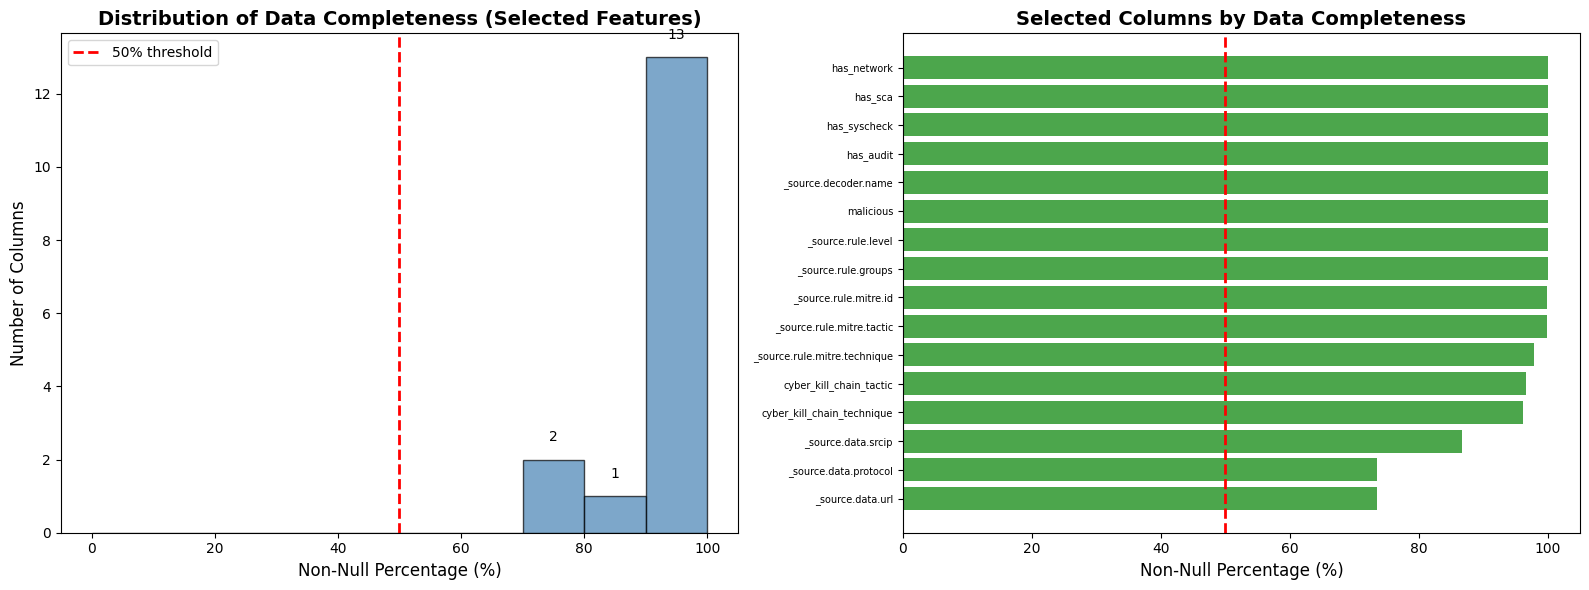


📈 COMPLETENESS SUMMARY (Selected Features):
   • Columns with 100% data: 8
   • Columns with ≥50% data: 16
   • Columns with ≥20% data: 16
   • Total selected: 16


In [7]:
# ============================================================================
# 📊 EXPLORATORY DATA ANALYSIS
# ============================================================================

print("=" * 70)
print("📊 EXPLORATORY DATA ANALYSIS")
print("=" * 70)

# Calculate missing values for selected columns
missing_pct = (df.isnull().sum() / len(df) * 100).sort_values(ascending=False)
non_null_pct = 100 - missing_pct

# Visualize missing values distribution
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Distribution of non-null percentages
ax1 = axes[0]
bins = [0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100]
hist_data = non_null_pct.values
counts, edges, patches = ax1.hist(hist_data, bins=bins, edgecolor='black', alpha=0.7, color='steelblue')
ax1.axvline(x=50, color='red', linestyle='--', linewidth=2, label='50% threshold')
ax1.set_xlabel('Non-Null Percentage (%)', fontsize=12)
ax1.set_ylabel('Number of Columns', fontsize=12)
ax1.set_title('Distribution of Data Completeness (Selected Features)', fontsize=14, fontweight='bold')
ax1.legend()

# Add count labels on bars
for count, edge in zip(counts, edges[:-1]):
    if count > 0:
        ax1.text(edge + 5, count + 0.5, f'{int(count)}', ha='center', fontsize=10)

# Plot 2: All selected columns by data completeness
ax2 = axes[1]
top_cols = non_null_pct.sort_values()
colors = ['green' if v >= 50 else 'orange' if v >= 20 else 'red' for v in top_cols.values]
bars = ax2.barh(range(len(top_cols)), top_cols.values, color=colors, alpha=0.7)
ax2.set_yticks(range(len(top_cols)))
ax2.set_yticklabels([c[:40] + '...' if len(c) > 40 else c for c in top_cols.index], fontsize=7)
ax2.axvline(x=50, color='red', linestyle='--', linewidth=2, label='50%')
ax2.set_xlabel('Non-Null Percentage (%)', fontsize=12)
ax2.set_title('Selected Columns by Data Completeness', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig(f"{CONFIG['output_dir']}/data_completeness.png", dpi=150, bbox_inches='tight')
plt.show()

# Summary statistics
cols_above_50 = (non_null_pct >= 50).sum()
cols_above_20 = (non_null_pct >= 20).sum()
cols_100 = (non_null_pct == 100).sum()

print(f"\n📈 COMPLETENESS SUMMARY (Selected Features):")
print(f"   • Columns with 100% data: {cols_100}")
print(f"   • Columns with ≥50% data: {cols_above_50}")
print(f"   • Columns with ≥20% data: {cols_above_20}")
print(f"   • Total selected: {len(non_null_pct)}")
print("=" * 70)

In [8]:
# ============================================================================
# 🔍 ANALYZE COLUMN TYPES FOR REaLTabFormer
# ============================================================================

print("=" * 70)
print("🔍 ANALYZING SELECTED COLUMN TYPES")
print("=" * 70)

def analyze_column(col_name, series):
    """Analyze a column and determine its type for REaLTabFormer"""
    non_null = series.dropna()
    n_unique = non_null.nunique()
    n_total = len(non_null)
    unique_ratio = n_unique / n_total if n_total > 0 else 0
    
    info = {
        'name': col_name,
        'dtype': str(series.dtype),
        'non_null_pct': (len(non_null) / len(series)) * 100,
        'n_unique': n_unique,
        'unique_ratio': unique_ratio,
        'sample_values': list(non_null.head(3).values) if n_total > 0 else [],
    }
    
    # Determine column category
    if series.dtype in ['int64', 'float64']:
        if n_unique <= 20:
            info['category'] = 'numeric_categorical'
        else:
            info['category'] = 'numeric'
    elif series.dtype == 'bool':
        info['category'] = 'boolean'
    elif series.dtype == 'object':
        # Check if it's a list/JSON field
        sample = str(non_null.iloc[0]) if n_total > 0 else ''
        if sample.startswith('[') or sample.startswith('{'):
            info['category'] = 'json_array'
        elif n_unique <= 100:
            info['category'] = 'categorical'
        elif unique_ratio > 0.95:
            info['category'] = 'high_cardinality'
        else:
            # Check average text length
            avg_len = non_null.astype(str).str.len().mean()
            if avg_len > 100:
                info['category'] = 'text_long'
            else:
                info['category'] = 'text_short'
        info['avg_length'] = non_null.astype(str).str.len().mean() if n_total > 0 else 0
    else:
        info['category'] = 'other'
    
    return info

# Analyze selected columns
column_analysis = []
for col in tqdm(df.columns, desc="Analyzing columns"):
    analysis = analyze_column(col, df[col])
    column_analysis.append(analysis)

analysis_df = pd.DataFrame(column_analysis)

# Display category distribution
print("\n📊 COLUMN CATEGORY DISTRIBUTION:")
print("-" * 70)
category_counts = analysis_df['category'].value_counts()
for cat, count in category_counts.items():
    print(f"   • {cat}: {count} columns")

# Display all columns with their categories
print("\n📋 ALL SELECTED COLUMNS:")
print("-" * 70)
for i, row in analysis_df.iterrows():
    status = "✅" if row['non_null_pct'] >= 50 else "⚠️" if row['non_null_pct'] >= 20 else "❌"
    print(f"   {status} {row['name'][:45]:<45} [{row['category']:<18}] ({row['non_null_pct']:.1f}%)")

print("\n" + "=" * 70)

🔍 ANALYZING SELECTED COLUMN TYPES


Analyzing columns:   0%|          | 0/16 [00:00<?, ?it/s]


📊 COLUMN CATEGORY DISTRIBUTION:
----------------------------------------------------------------------
   • categorical: 5 columns
   • boolean: 4 columns
   • json_array: 4 columns
   • numeric_categorical: 2 columns
   • text_long: 1 columns

📋 ALL SELECTED COLUMNS:
----------------------------------------------------------------------
   ✅ malicious                                     [numeric_categorical] (100.0%)
   ✅ cyber_kill_chain_tactic                       [categorical       ] (96.6%)
   ✅ cyber_kill_chain_technique                    [categorical       ] (96.1%)
   ✅ _source.rule.mitre.tactic                     [json_array        ] (99.9%)
   ✅ _source.rule.mitre.technique                  [json_array        ] (97.9%)
   ✅ _source.rule.mitre.id                         [json_array        ] (100.0%)
   ✅ _source.rule.level                            [numeric_categorical] (100.0%)
   ✅ _source.rule.groups                           [json_array        ] (100.0%)
   ✅ _source.

## 🔧 Section 3: Data Preprocessing for REaLTabFormer

REaLTabFormer works best with:
- **Text columns** - Kept as-is (no embedding needed!)
- **Categorical columns** - Kept as-is (handles natively)
- **Numeric columns** - Kept as-is
- **Missing values** - Handled automatically

Since we're using **predefined feature-selected columns**, we skip automatic column selection and directly preprocess the data:
1. Truncate very long text fields
2. Handle missing values appropriately
3. Categorize columns by type

In [9]:
# ============================================================================
# 🔧 USING PREDEFINED COLUMNS (Feature Selection Already Done)
# ============================================================================

print("=" * 70)
print("🔧 USING PREDEFINED FEATURE-SELECTED COLUMNS")
print("=" * 70)

# We already have df with the selected columns from data loading
selected_columns = list(df.columns)

print(f"\n✅ WORKING WITH {len(selected_columns)} COLUMNS:")
print(f"   • Core features (≥50% complete): {len(REALTABFORMER_COLUMNS)}")
print(f"   • Boolean flags (created): 4")

# Show columns by category
print(f"\n📋 COLUMNS BY CATEGORY:")
print("-" * 70)

# Group columns logically
column_groups = {
    'Target': ['malicious'],
    'Cyber Kill Chain': [c for c in selected_columns if 'cyber_kill_chain' in c],
    'MITRE ATT&CK': [c for c in selected_columns if 'mitre' in c.lower() and 'sca' not in c],
    'Rule/Decoder': [c for c in selected_columns if any(x in c for x in ['rule.level', 'rule.groups', 'decoder'])],
    'Network': [c for c in selected_columns if any(x in c for x in ['protocol', 'srcip', 'url'])],
    'Boolean Flags': [c for c in selected_columns if c.startswith('has_')],
}

for group, cols in column_groups.items():
    if cols:
        print(f"\n   {group} ({len(cols)}):")
        for col in cols:
            non_null = df[col].notna().sum() / len(df) * 100
            dtype = df[col].dtype
            print(f"      • {col}: {non_null:.1f}% non-null, dtype={dtype}")

print("\n" + "=" * 70)

🔧 USING PREDEFINED FEATURE-SELECTED COLUMNS

✅ WORKING WITH 16 COLUMNS:
   • Core features (≥50% complete): 12
   • Boolean flags (created): 4

📋 COLUMNS BY CATEGORY:
----------------------------------------------------------------------

   Target (1):
      • malicious: 100.0% non-null, dtype=int64

   Cyber Kill Chain (2):
      • cyber_kill_chain_tactic: 96.6% non-null, dtype=object
      • cyber_kill_chain_technique: 96.1% non-null, dtype=object

   MITRE ATT&CK (3):
      • _source.rule.mitre.tactic: 99.9% non-null, dtype=object
      • _source.rule.mitre.technique: 97.9% non-null, dtype=object
      • _source.rule.mitre.id: 100.0% non-null, dtype=object

   Rule/Decoder (3):
      • _source.rule.level: 100.0% non-null, dtype=int64
      • _source.rule.groups: 100.0% non-null, dtype=object
      • _source.decoder.name: 100.0% non-null, dtype=object

   Network (3):
      • _source.data.protocol: 73.5% non-null, dtype=object
      • _source.data.srcip: 86.7% non-null, dtype=object

In [10]:
# ============================================================================
# 🔄 PREPROCESS DATA FOR REaLTabFormer
# ============================================================================

print("=" * 70)
print("🔄 PREPROCESSING DATA")
print("=" * 70)

print(f"   • Initial shape: {df.shape}")

# Process each column type based on analysis
text_columns = []
categorical_columns = []
numeric_columns = []

for col in df.columns:
    col_info = analysis_df[analysis_df['name'] == col].iloc[0]
    
    if col_info['category'] in ['text_long', 'text_short']:
        text_columns.append(col)
        # Truncate very long text to prevent token overflow
        max_len = 500 if col_info['category'] == 'text_long' else 200
        df[col] = df[col].fillna('').astype(str).str[:max_len]
        
    elif col_info['category'] in ['categorical', 'boolean', 'json_array']:
        categorical_columns.append(col)
        # Convert to string for REaLTabFormer
        df[col] = df[col].fillna('MISSING').astype(str)
        
    elif col_info['category'] in ['numeric', 'numeric_categorical']:
        numeric_columns.append(col)
        # Keep numeric as-is, REaLTabFormer handles NaN
        
    else:
        # Default to categorical treatment
        categorical_columns.append(col)
        df[col] = df[col].fillna('MISSING').astype(str)

# Handle any remaining NaN in text columns
for col in text_columns:
    df[col] = df[col].replace('nan', '').replace('None', '')

print(f"\n📊 COLUMN TYPE SUMMARY:")
print(f"   • Text columns: {len(text_columns)}")
print(f"   • Categorical columns: {len(categorical_columns)}")
print(f"   • Numeric columns: {len(numeric_columns)}")

print(f"\n📋 TEXT COLUMNS ({len(text_columns)}):")
for col in text_columns:
    avg_len = df[col].str.len().mean()
    print(f"   • {col}: avg length {avg_len:.0f} chars")

print(f"\n📋 CATEGORICAL COLUMNS ({len(categorical_columns)}):")
for col in categorical_columns[:15]:  # Show first 15
    n_unique = df[col].nunique()
    print(f"   • {col}: {n_unique} unique values")
if len(categorical_columns) > 15:
    print(f"   ... and {len(categorical_columns) - 15} more")

print(f"\n📋 NUMERIC COLUMNS ({len(numeric_columns)}):")
for col in numeric_columns:
    print(f"   • {col}: range [{df[col].min():.2f}, {df[col].max():.2f}]")

print(f"\n✅ Final preprocessed shape: {df.shape}")
print("=" * 70)

🔄 PREPROCESSING DATA
   • Initial shape: (25418, 16)

📊 COLUMN TYPE SUMMARY:
   • Text columns: 1
   • Categorical columns: 13
   • Numeric columns: 2

📋 TEXT COLUMNS (1):
   • _source.data.url: avg length 107 chars

📋 CATEGORICAL COLUMNS (13):
   • cyber_kill_chain_tactic: 6 unique values
   • cyber_kill_chain_technique: 6 unique values
   • _source.rule.mitre.tactic: 27 unique values
   • _source.rule.mitre.technique: 28 unique values
   • _source.rule.mitre.id: 81 unique values
   • _source.rule.groups: 22 unique values
   • _source.decoder.name: 12 unique values
   • _source.data.protocol: 23 unique values
   • _source.data.srcip: 4 unique values
   • has_audit: 2 unique values
   • has_syscheck: 2 unique values
   • has_sca: 2 unique values
   • has_network: 2 unique values

📋 NUMERIC COLUMNS (2):
   • malicious: range [1.00, 1.00]
   • _source.rule.level: range [3.00, 15.00]

✅ Final preprocessed shape: (25418, 16)


In [11]:
# ============================================================================
# 📊 VISUALIZE PREPROCESSED DATA
# ============================================================================

print("=" * 70)
print("📊 VISUALIZING PREPROCESSED DATA")
print("=" * 70)

# Create visualization
fig = make_subplots(
    rows=2, cols=2,
    subplot_titles=(
        'Column Type Distribution',
        'Data Completeness (Preprocessed)',
        'Top Categorical Value Counts',
        'Numeric Feature Distributions'
    ),
    specs=[[{"type": "pie"}, {"type": "bar"}],
           [{"type": "bar"}, {"type": "box"}]]
)

# 1. Column type distribution (pie)
type_counts = pd.Series({
    'Text': len(text_columns),
    'Categorical': len(categorical_columns),
    'Numeric': len(numeric_columns)
})
fig.add_trace(
    go.Pie(labels=type_counts.index, values=type_counts.values,
           marker_colors=['#2ecc71', '#3498db', '#e74c3c']),
    row=1, col=1
)

# 2. Data completeness
completeness = (df.notna().sum() / len(df) * 100).sort_values(ascending=True).tail(20)
fig.add_trace(
    go.Bar(x=completeness.values, y=[c[:30] for c in completeness.index],
           orientation='h', marker_color='steelblue'),
    row=1, col=2
)

# 3. Top categorical value counts (for first categorical column with reasonable cardinality)
cat_col = None
for c in categorical_columns:
    if df[c].nunique() <= 20:
        cat_col = c
        break

if cat_col:
    value_counts = df[cat_col].value_counts().head(10)
    fig.add_trace(
        go.Bar(x=value_counts.values, y=[str(v)[:20] for v in value_counts.index],
               orientation='h', marker_color='coral'),
        row=2, col=1
    )
    fig.update_yaxes(title_text=cat_col[:30], row=2, col=1)

# 4. Numeric distributions
if numeric_columns:
    for col in numeric_columns[:5]:
        fig.add_trace(
            go.Box(y=df[col].dropna(), name=col[:20], boxpoints='outliers'),
            row=2, col=2
        )

fig.update_layout(
    height=800,
    title_text="📊 Preprocessed Data Overview",
    showlegend=False
)
fig.show()

# Save figure
fig.write_html(f"{CONFIG['output_dir']}/preprocessed_data_overview.html")
print(f"✅ Visualization saved to {CONFIG['output_dir']}/preprocessed_data_overview.html")
print("=" * 70)

📊 VISUALIZING PREPROCESSED DATA


✅ Visualization saved to /kaggle/working/realtabformer_output/preprocessed_data_overview.html


## 🧬 Section 4: REaLTabFormer Model Training

REaLTabFormer uses a GPT-2 based architecture to learn tabular data:

1. **Tokenization**: Each row is converted to text format:
   ```
   "column1 is value1, column2 is value2, ..."
   ```

2. **Training**: GPT-2 learns to predict the next token autoregressively

3. **Generation**: New rows are sampled token-by-token

### Key Advantages:
- 🎯 **No embedding needed** - Text columns handled natively
- 🔗 **Column relationships** - Attention mechanism learns correlations
- 📊 **Mixed types** - Handles categorical, numeric, text together
- ❓ **Missing values** - Native support as tokens

In [12]:
# ============================================================================
# 🔍 VERIFY GPU USAGE
# ============================================================================

print("=" * 70)
print("🔍 VERIFYING GPU USAGE")
print("=" * 70)

if device == "cuda":
    print(f"✅ CUDA is available and will be used!")
    print(f"\n📊 GPU STATUS:")
    print(f"   • GPU Name: {torch.cuda.get_device_name(0)}")
    print(f"   • GPU Memory Total: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
    print(f"   • GPU Memory Allocated: {torch.cuda.memory_allocated(0) / 1e9:.4f} GB")
    print(f"   • GPU Memory Cached: {torch.cuda.memory_reserved(0) / 1e9:.4f} GB")
    print(f"   • CUDA Capability: {torch.cuda.get_device_capability(0)}")
    
    # REaLTabFormer uses Hugging Face transformers which auto-detects GPU
    # Check if transformers will use GPU by default
    try:
        from transformers import AutoTokenizer
        print(f"\n🧪 VERIFYING TRANSFORMERS GPU AUTO-DETECTION:")
        # REaLTabFormer uses GPT-2, which transformers will put on GPU if available
        print(f"   • REaLTabFormer uses Hugging Face transformers (GPT-2)")
        print(f"   • Transformers library automatically uses GPU when available")
        print(f"   ✅ Model will use GPU during training!")
        
        # Show that transformers detects CUDA
        import transformers
        print(f"   • Transformers version: {transformers.__version__}")
        print(f"   • CUDA visible to transformers: {torch.cuda.is_available()}")
    except Exception as e:
        print(f"   ⚠️ Could not verify transformers GPU detection: {e}")
    
    print(f"\n💡 TIP: Monitor GPU usage during training with:")

    print(f"   nvidia-smi -l 1  # (in separate terminal)")
else:
    print(f"⚠️ CUDA not available - model will use CPU (training will be slower)")

print("=" * 70)


🔍 VERIFYING GPU USAGE
✅ CUDA is available and will be used!

📊 GPU STATUS:
   • GPU Name: Tesla T4
   • GPU Memory Total: 15.83 GB
   • GPU Memory Allocated: 0.0000 GB
   • GPU Memory Cached: 0.0000 GB
   • CUDA Capability: (7, 5)

🧪 VERIFYING TRANSFORMERS GPU AUTO-DETECTION:
   • REaLTabFormer uses Hugging Face transformers (GPT-2)
   • Transformers library automatically uses GPU when available
   ✅ Model will use GPU during training!
   • Transformers version: 4.57.1
   • CUDA visible to transformers: True

💡 TIP: Monitor GPU usage during training with:
   nvidia-smi -l 1  # (in separate terminal)


In [14]:
# ============================================================================
# 🧬 INITIALIZE REaLTabFormer MODEL
# ============================================================================

import os

print("=" * 70)
print("🧬 INITIALIZING REaLTabFormer MODEL")
print("=" * 70)

# Environment settings
os.environ["WANDB_DISABLED"] = "true"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["WANDB_MODE"] = "disabled"

# Initialize model using CONFIG
rtf_model = REaLTabFormer(
    model_type=CONFIG['model_type'],
    gradient_accumulation_steps=CONFIG['gradient_accumulation_steps'],
    logging_steps=CONFIG['logging_steps'],
    save_steps=CONFIG['save_steps'],
    epochs=CONFIG['epochs'],
    batch_size=CONFIG['batch_size'],
    train_size=CONFIG['train_size'],
    random_state=CONFIG['random_seed'],
    checkpoints_dir=CONFIG['checkpoints_dir'],
)

rtf_model.experiment_id = CONFIG['experiment_id']

print(f"✅ Model initialized!")
print(f"💾 Checkpoints: {CONFIG['checkpoints_dir']}")
print(f"🔑 Experiment ID: {CONFIG['experiment_id']}")
print(f"\n⚙️ SETTINGS:")
print(f"   • Model type: {CONFIG['model_type']}")
print(f"   • Epochs: {CONFIG['epochs']}")
print(f"   • Batch size: {CONFIG['batch_size']}")
print(f"   • Gradient accumulation: {CONFIG['gradient_accumulation_steps']}")
print(f"   • Train/Val split: {CONFIG['train_size']}/{1-CONFIG['train_size']}")
print(f"   • Device: {CONFIG['device'].upper()}")

if torch.cuda.is_available():
    gpu_count = torch.cuda.device_count()
    print(f"   ✅ {gpu_count} GPUs available ({torch.cuda.get_device_properties(0).total_memory / 1e9:.1f}GB each)")
else:
    print("   ❌ No GPUs detected!")

samples = len(df)
steps_per_epoch = samples // CONFIG['batch_size']
print(f"\n⏱️ ESTIMATE: {samples:,} samples, ~{steps_per_epoch} steps/epoch")
print("=" * 70)

🧬 INITIALIZING REaLTabFormer MODEL
✅ Model initialized!
💾 Checkpoints: /kaggle/working/realtabformer_checkpoints
🔑 Experiment ID: apt_augmentation_20260112_093459

⚙️ SETTINGS:
   • Model type: tabular
   • Epochs: 150
   • Batch size: 32
   • Gradient accumulation: 4
   • Train/Val split: 0.95/0.050000000000000044
   • Device: CUDA
   ✅ 2 GPUs available (15.8GB each)

⏱️ ESTIMATE: 25,418 samples, ~794 steps/epoch


In [15]:
# ============================================================================
# 🚀 TRAIN REaLTabFormer MODEL (WITH SENSITIVITY BYPASS)
# ============================================================================

from glob import glob
from datetime import datetime
from pathlib import Path
import shutil
import warnings
import types
import json
import numpy as np

print("=" * 70)
print("🚀 TRAINING REaLTabFormer MODEL")
print("=" * 70)

# ===== PATCH TO SKIP SENSITIVITY THRESHOLD COMPUTATION (~1h 45min saved!) =====
# Uses pre-computed threshold: 0.16750709503093994
print("   ⚡ Injecting pre-computed sensitivity threshold...")

try:
    from realtabformer.rtf_validators import SyntheticDataBench
except ImportError:
    try:
        import realtabformer.realtabformer as rtf_module
        SyntheticDataBench = rtf_module.SyntheticDataBench
    except:
        SyntheticDataBench = None

if SyntheticDataBench:
    PRECOMPUTED_THRESHOLD = 0.16750709503093994
    
    def patched_compute_sensitivity_threshold(*args, **kwargs):
        print(f"   ✅ Using pre-computed threshold: {PRECOMPUTED_THRESHOLD}")
        return np.array([PRECOMPUTED_THRESHOLD] * 10)
    
    SyntheticDataBench.compute_sensitivity_threshold = staticmethod(patched_compute_sensitivity_threshold)
    print("   ✅ Sensitivity bypass applied!")
else:
    print("   ⚠️ Could not patch SyntheticDataBench - will compute threshold normally")

# ===== PATCH SAVE METHOD TO HANDLE DATASET OBJECTS =====
def patched_save(self, path, allow_overwrite=False):
    """Patched save method that handles non-JSON-serializable objects."""
    path = Path(path)
    path.mkdir(parents=True, exist_ok=True)
    config_file = path / "rtf_config.json"
    
    rtf_attrs = {}
    for key, value in self.__dict__.items():
        if key.startswith('_') and key != '_column_order':
            continue
        if key in ['model', 'trainer', 'tokenizer', 'data_collator']:
            continue
        try:
            json.dumps(value, default=str)
            if isinstance(value, Path):
                rtf_attrs[key] = value.as_posix()
            elif hasattr(value, '__class__') and value.__class__.__name__ == 'Dataset':
                continue
            else:
                rtf_attrs[key] = value
        except (TypeError, ValueError):
            continue
    
    for attr in ["checkpoints_dir", "samples_save_dir", "full_save_dir"]:
        if attr in rtf_attrs and hasattr(rtf_attrs[attr], 'as_posix'):
            rtf_attrs[attr] = rtf_attrs[attr].as_posix()
    
    def json_encoder(obj):
        if isinstance(obj, Path):
            return obj.as_posix()
        if hasattr(obj, 'tolist'):
            return obj.tolist()
        return str(obj)
    
    config_file.write_text(json.dumps(rtf_attrs, default=json_encoder, indent=2))
    
    if hasattr(self, 'model') and self.model is not None:
        self.model.save_pretrained(path)
    if hasattr(self, 'tokenizer') and self.tokenizer is not None:
        self.tokenizer.save_pretrained(path)

rtf_model.save = types.MethodType(patched_save, rtf_model)

# ===== AUTO-RESUME FROM CHECKPOINT =====
checkpoint_pattern = os.path.join(CONFIG['checkpoints_dir'], "checkpoint-*")
latest_checkpoint = None

if glob(checkpoint_pattern):
    checkpoints = sorted(
        [d for d in glob(checkpoint_pattern) if os.path.isdir(d)],
        key=lambda x: int(x.split('-')[-1])
    )
    if checkpoints:
        latest_checkpoint = checkpoints[-1]
        print(f"   ✅ RESUMING from: {os.path.basename(latest_checkpoint)}")
    else:
        print("   🆕 STARTING FRESH")
else:
    print("   🆕 STARTING FRESH")

print(f"   🖥️  GPUs: {torch.cuda.device_count()}")

# ===== TRAIN =====
train_start = datetime.now()
print(f"   🕐 Started: {train_start.strftime('%Y-%m-%d %H:%M:%S')}")
print("=" * 70)

warnings.filterwarnings('ignore')

try:
    rtf_model.fit(
        df,
        resume_from_checkpoint=latest_checkpoint,
        device=CONFIG['device'],
        gen_kwargs={},  # Fix for **None error
    )
except Exception as e:
    print(f"\n❌ Error: {e}")
    import traceback
    traceback.print_exc()
    raise

# ===== SUMMARY =====
train_end = datetime.now()
train_duration = (train_end - train_start).total_seconds() / 60

print("\n" + "=" * 70)
print(f"✅ TRAINING COMPLETE! Duration: {train_duration:.1f} min")
print("=" * 70)

# Disk space check
total, used, free = shutil.disk_usage("/kaggle/working")
print(f"💾 Disk remaining: {free / (2**30):.2f} GB")

# ===== BACKUP FINAL MODEL =====
final_checkpoints = sorted(glob(checkpoint_pattern), key=lambda x: int(x.split('-')[-1]))
if final_checkpoints:
    latest = final_checkpoints[-1]
    print(f"\n📤 BACKING UP: {latest} → {CONFIG['backup_dir']}")
    
    essential_files = [
        "config.json", "pytorch_model.bin", "model.safetensors",
        "special_tokens_map.json", "tokenizer.json", 
        "tokenizer_config.json", "rtf_config.json",
    ]
    
    for file in essential_files:
        src = os.path.join(latest, file)
        if os.path.exists(src):
            shutil.copy2(src, CONFIG['backup_dir'])
            print(f"   ✅ {file}")
    
    print(f"\n🎉 Model backed up to: {CONFIG['backup_dir']}")
else:
    print("\n❌ No checkpoints found!")

print("=" * 70)

🚀 TRAINING REaLTabFormer MODEL
   ⚡ Injecting pre-computed sensitivity threshold...
   ✅ Sensitivity bypass applied!
   🆕 STARTING FRESH
   🖥️  GPUs: 2
   🕐 Started: 2026-01-12 09:40:00
Computing the sensitivity threshold...
   ✅ Using pre-computed threshold: 0.16750709503093994
Sensitivity threshold: 0.16750709503093994 qt_max: 0.05


Map:   0%|          | 0/25418 [00:00<?, ? examples/s]

Using the `WANDB_DISABLED` environment variable is deprecated and will be removed in v5. Use the --report_to flag to control the integrations used for logging result (for instance --report_to none).
`loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.
`loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Step,Training Loss,Validation Loss
100,1.020900,0.522916
200,0.510500,0.508246
300,0.489500,0.503978
400,0.477900,0.503959


  0%|          | 0/12579 [00:00<?, ?it/s]

Generated 0 invalid samples out of total 12672 samples generated. Sampling efficiency is: 100.0000%
Saving not-best model...


... (8 outputs left out)

Step,Training Loss,Validation Loss
1000,0.448000,0.507336
1100,0.449700,0.512078
1200,0.446400,0.513000
1300,0.445400,0.515970
1400,0.444100,0.515123


There were missing keys in the checkpoint model loaded: ['lm_head.weight'].


  0%|          | 0/12579 [00:00<?, ?it/s]

Generated 0 invalid samples out of total 12672 samples generated. Sampling efficiency is: 100.0000%
Critic round: 15,                     sensitivity_threshold: 0.16750709503093994,                         val_sensitivity: 0.21835402853511393,                             val_sensitivities: [np.float64(0.22099999999999997), np.float64(0.21940116845180135), np.float64(0.21833515515880245), np.float64(0.22074623237724839), np.float64(0.218946952183964), np.float64(0.21517759396667072), np.float64(0.215095087163233), np.float64(0.22076220063944021), np.float64(0.21728807384017493), np.float64(0.21716472303207), np.float64(0.2213152787044338), np.float64(0.2129301957922899), np.float64(0.22099514563106795), np.float64(0.2195566232818392), np.float64(0.21659599780367278)]
Stopping training, no improvement in critic...

✅ TRAINING COMPLETE! Duration: 38.9 min
💾 Disk remaining: 14.95 GB

📤 BACKING UP: /kaggle/working/realtabformer_checkpoints/checkpoint-1400 → /kaggle/working/final_model
   ✅ 

### Restore Model


from glob import glob
import os

checkpoint_pattern = os.path.join(CONFIG['checkpoints_dir'], "checkpoint-*")
checkpoints = sorted(glob(checkpoint_pattern))

if checkpoints:
    print(f"✅ Found {len(checkpoints)} checkpoint(s):")
    for cp in checkpoints:
        print(f"   - {cp}")
    latest_checkpoint = checkpoints[-1]
    print(f"\n🎯 Will resume from: {latest_checkpoint}")
else:
    print("❌ No checkpoints found - will need to restart")

import numpy as np

# Try to find the correct import path
try:
    from realtabformer.rtf_validators import SyntheticDataBench
except ImportError:
    try:
        from realtabformer.realtabformer import SyntheticDataBench
    except ImportError:
        # Find it dynamically
        import realtabformer
        SyntheticDataBench = getattr(realtabformer, 'SyntheticDataBench', None)
        if SyntheticDataBench is None:
            # Last resort: patch at the module level
            import realtabformer.realtabformer as rtf_module
            SyntheticDataBench = rtf_module.SyntheticDataBench

# Create patched version that returns your known threshold
def patched_compute_sensitivity_threshold(*args, **kwargs):
    print("✅ Using pre-computed sensitivity threshold: 0.16750709503093994")
    return np.array([0.16750709503093994] * 10)

# Apply the patch
SyntheticDataBench.compute_sensitivity_threshold = staticmethod(patched_compute_sensitivity_threshold)

# Now run training
rtf_model.fit(
    df,
    resume_from_checkpoint="./realtabformer_checkpoints/checkpoint-900",
    device=CONFIG['device'],
    gen_kwargs={},
)

In [16]:
# ============================================================================
# 💾 SAVE TRAINED MODEL
# ============================================================================

print("=" * 70)
print("💾 SAVING TRAINED MODEL")
print("=" * 70)

# Save the model
model_path = f"{CONFIG['output_dir']}/realtabformer_model"
rtf_model.save(model_path)

print(f"✅ Model saved to: {model_path}")

# Save training configuration
config_path = f"{CONFIG['output_dir']}/training_config.json"
with open(config_path, 'w') as f:
    json.dump({
        'config': {k: v for k, v in CONFIG.items() if not isinstance(v, list)},
        'selected_columns': selected_columns,
        'text_columns': text_columns,
        'categorical_columns': categorical_columns,
        'numeric_columns': numeric_columns,
        'training_duration_minutes': train_duration,
        'original_shape': list(raw_data.shape),
        'processed_shape': list(df.shape),
    }, f, indent=2)

print(f"✅ Configuration saved to: {config_path}")
print("=" * 70)

💾 SAVING TRAINED MODEL
✅ Model saved to: /kaggle/working/realtabformer_output/realtabformer_model
✅ Configuration saved to: /kaggle/working/realtabformer_output/training_config.json


## 🔄 Section 5: Synthetic Data Generation

Now we use the trained model to generate synthetic APT data. REaLTabFormer generates data by:

1. Starting with beginning-of-sequence token
2. Autoregressively predicting each column value
3. Converting generated tokens back to tabular format

In [17]:
# ============================================================================
# 🔄 GENERATE SYNTHETIC DATA
# ============================================================================

print("=" * 70)
print("🔄 GENERATING SYNTHETIC DATA")
print("=" * 70)

# Calculate number of samples to generate
n_real = len(df)
n_synthetic = int(n_real * CONFIG['synthetic_ratio'])

print(f"\n📊 GENERATION PLAN:")
print(f"   • Original samples: {n_real:,}")
print(f"   • Synthetic ratio: {CONFIG['synthetic_ratio']}x")
print(f"   • Target synthetic: {n_synthetic:,}")

# Generate synthetic data
gen_start = datetime.now()
print(f"\n🔄 Generating {n_synthetic:,} synthetic samples...")
print(f"   🕐 Started at: {gen_start.strftime('%H:%M:%S')}")
print("-" * 70)

# Generate in batches for memory efficiency
synthetic_samples = rtf_model.sample(
    n_samples=n_synthetic,
    # gen_batch=CONFIG['generation_batch_size'],  # Uncomment if supported
)

gen_end = datetime.now()
gen_duration = (gen_end - gen_start).total_seconds() / 60

print("-" * 70)
print(f"\n✅ SYNTHETIC DATA GENERATED!")
print(f"   • Shape: {synthetic_samples.shape}")
print(f"   • Generation time: {gen_duration:.1f} minutes")
print(f"   • Columns match: {list(synthetic_samples.columns) == list(df.columns)}")
print("=" * 70)

🔄 GENERATING SYNTHETIC DATA

📊 GENERATION PLAN:
   • Original samples: 25,418
   • Synthetic ratio: 2.0x
   • Target synthetic: 50,836

🔄 Generating 50,836 synthetic samples...
   🕐 Started at: 10:29:57
----------------------------------------------------------------------


  0%|          | 0/50836 [00:00<?, ?it/s]

Generated 0 invalid samples out of total 50944 samples generated. Sampling efficiency is: 100.0000%
----------------------------------------------------------------------

✅ SYNTHETIC DATA GENERATED!
   • Shape: (50836, 16)
   • Generation time: 3.6 minutes
   • Columns match: True


In [18]:
# ============================================================================
# 👀 PREVIEW SYNTHETIC DATA
# ============================================================================

print("=" * 70)
print("👀 SYNTHETIC DATA PREVIEW")
print("=" * 70)

# Compare real vs synthetic samples
print("\n📋 REAL DATA (first 3 rows):")
print("-" * 70)
display_cols = [c for c in df.columns if df[c].dtype in ['object', 'int64', 'float64']][:8]
print(df[display_cols].head(3).to_string())

print("\n📋 SYNTHETIC DATA (first 3 rows):")
print("-" * 70)
print(synthetic_samples[display_cols].head(3).to_string())

# Show text column comparison
if text_columns:
    print(f"\n📝 TEXT COLUMN COMPARISON: {text_columns[0]}")
    print("-" * 70)
    print(f"   REAL: {df[text_columns[0]].iloc[0][:200]}...")
    print(f"   SYNTH: {synthetic_samples[text_columns[0]].iloc[0][:200]}...")

# Show categorical distribution comparison
print("\n📊 CATEGORICAL DISTRIBUTION COMPARISON:")
print("-" * 70)
for col in categorical_columns[:3]:
    print(f"\n   {col}:")
    real_dist = df[col].value_counts(normalize=True).head(5)
    synth_dist = synthetic_samples[col].value_counts(normalize=True).head(5)
    print(f"      Real top 5:  {dict(real_dist.round(3))}")
    print(f"      Synth top 5: {dict(synth_dist.round(3))}")

print("\n" + "=" * 70)

👀 SYNTHETIC DATA PREVIEW

📋 REAL DATA (first 3 rows):
----------------------------------------------------------------------
   malicious cyber_kill_chain_tactic cyber_kill_chain_technique              _source.rule.mitre.tactic _source.rule.mitre.technique _source.rule.mitre.id  _source.rule.level                        _source.rule.groups
0          1                      S4                         S4                    ["TA0004","TA0005"]    ["Sudo and Sudo Caching"]         ["T1548.003"]                   3                          ["syslog","sudo"]
1          1                      S3                         S3  ["TA0005","TA0003","TA0004","TA0001"]           ["Valid Accounts"]             ["T1078"]                   3  ["pam","syslog","authentication_success"]
2          1                      S4                         S4                    ["TA0004","TA0005"]    ["Sudo and Sudo Caching"]         ["T1548.003"]                   3                          ["syslog","sudo"]

📋 SYNT

## 📊 Section 6: Quality Validation

Comprehensive quality assessment comparing synthetic vs real data:

1. **Statistical Tests**
   - KS Test (Kolmogorov-Smirnov) for numeric columns
   - Chi-Square / L1 Distance for categorical columns

2. **Distribution Comparison**
   - Visual comparison of distributions
   - Coverage analysis

3. **ML Utility Test (TSTR)**
   - Train on Synthetic, Test on Real
   - Measures if synthetic data is useful for ML tasks

In [19]:
# ============================================================================
# 📊 COMPREHENSIVE QUALITY VALIDATION
# ============================================================================

print("=" * 70)
print("📊 COMPREHENSIVE QUALITY VALIDATION")
print("=" * 70)

def evaluate_quality(real_df, synth_df, numeric_cols, categorical_cols, 
                     ks_threshold=0.3, l1_threshold=0.3):
    """
    Comprehensive quality evaluation for synthetic data
    """
    results = {
        'numeric': [],
        'categorical': [],
        'summary': {}
    }
    
    # Evaluate numeric columns
    print("\n🔢 NUMERIC FEATURES (KS Test):")
    print("-" * 70)
    print(f"{'Feature':<45} {'KS Stat':<12} {'P-Value':<12} {'Quality':<12}")
    print("-" * 70)
    
    for col in numeric_cols:
        if col in real_df.columns and col in synth_df.columns:
            real_vals = real_df[col].dropna().values
            synth_vals = synth_df[col].dropna().values
            
            if len(real_vals) > 0 and len(synth_vals) > 0:
                ks_stat, p_value = ks_2samp(real_vals, synth_vals)
                
                if ks_stat < 0.1:
                    quality = "🟢 EXCELLENT"
                elif ks_stat < 0.2:
                    quality = "🟡 GOOD"
                elif ks_stat < ks_threshold:
                    quality = "🟠 MODERATE"
                else:
                    quality = "🔴 POOR"
                
                results['numeric'].append({
                    'column': col,
                    'ks_stat': ks_stat,
                    'p_value': p_value,
                    'quality': quality
                })
                
                print(f"{col[:45]:<45} {ks_stat:<12.4f} {p_value:<12.4f} {quality:<12}")
    
    # Evaluate categorical columns
    print("\n🏷️ CATEGORICAL FEATURES (L1 Distance):")
    print("-" * 70)
    print(f"{'Feature':<45} {'L1 Dist':<12} {'Coverage':<12} {'Quality':<12}")
    print("-" * 70)
    
    for col in categorical_cols:
        if col in real_df.columns and col in synth_df.columns:
            real_dist = real_df[col].value_counts(normalize=True)
            synth_dist = synth_df[col].value_counts(normalize=True)
            
            # Align distributions
            all_categories = set(real_dist.index) | set(synth_dist.index)
            real_aligned = pd.Series({c: real_dist.get(c, 0) for c in all_categories})
            synth_aligned = pd.Series({c: synth_dist.get(c, 0) for c in all_categories})
            
            # L1 distance
            l1_dist = np.abs(real_aligned - synth_aligned).sum()
            
            # Coverage
            real_cats = set(real_dist.index)
            synth_cats = set(synth_dist.index)
            coverage = len(real_cats & synth_cats) / len(real_cats) * 100 if len(real_cats) > 0 else 0
            
            if l1_dist < 0.1:
                quality = "🟢 EXCELLENT"
            elif l1_dist < 0.2:
                quality = "🟡 GOOD"
            elif l1_dist < l1_threshold:
                quality = "🟠 MODERATE"
            else:
                quality = "🔴 POOR"
            
            results['categorical'].append({
                'column': col,
                'l1_dist': l1_dist,
                'coverage': coverage,
                'quality': quality
            })
            
            print(f"{col[:45]:<45} {l1_dist:<12.4f} {coverage:<11.1f}% {quality:<12}")
    
    # Calculate summary
    numeric_good = sum(1 for r in results['numeric'] if '🟢' in r['quality'] or '🟡' in r['quality'])
    cat_good = sum(1 for r in results['categorical'] if '🟢' in r['quality'] or '🟡' in r['quality'])
    
    results['summary'] = {
        'numeric_total': len(results['numeric']),
        'numeric_good': numeric_good,
        'categorical_total': len(results['categorical']),
        'categorical_good': cat_good,
        'avg_ks': np.mean([r['ks_stat'] for r in results['numeric']]) if results['numeric'] else 0,
        'avg_l1': np.mean([r['l1_dist'] for r in results['categorical']]) if results['categorical'] else 0,
        'avg_coverage': np.mean([r['coverage'] for r in results['categorical']]) if results['categorical'] else 0,
    }
    
    return results

# Run quality evaluation
quality_results = evaluate_quality(
    df, synthetic_samples,
    numeric_columns, categorical_columns,
    CONFIG['ks_threshold'], CONFIG['l1_threshold']
)

print("\n" + "=" * 70)

📊 COMPREHENSIVE QUALITY VALIDATION

🔢 NUMERIC FEATURES (KS Test):
----------------------------------------------------------------------
Feature                                       KS Stat      P-Value      Quality     
----------------------------------------------------------------------
malicious                                     0.0000       1.0000       🟢 EXCELLENT 
_source.rule.level                            0.0398       0.0000       🟢 EXCELLENT 

🏷️ CATEGORICAL FEATURES (L1 Distance):
----------------------------------------------------------------------
Feature                                       L1 Dist      Coverage     Quality     
----------------------------------------------------------------------
cyber_kill_chain_tactic                       0.0527       100.0      % 🟢 EXCELLENT 
cyber_kill_chain_technique                    0.0432       100.0      % 🟢 EXCELLENT 
_source.rule.mitre.tactic                     0.2074       100.0      % 🟠 MODERATE  
_source.rule.mi

In [20]:
# ============================================================================
# 📊 QUALITY SUMMARY REPORT
# ============================================================================

print("=" * 70)
print("📊 QUALITY SUMMARY REPORT")
print("=" * 70)

summary = quality_results['summary']

# Count quality levels
def count_quality(results_list, level):
    return sum(1 for r in results_list if level in r['quality'])

numeric_excellent = count_quality(quality_results['numeric'], '🟢')
numeric_good = count_quality(quality_results['numeric'], '🟡')
numeric_moderate = count_quality(quality_results['numeric'], '🟠')
numeric_poor = count_quality(quality_results['numeric'], '🔴')

cat_excellent = count_quality(quality_results['categorical'], '🟢')
cat_good = count_quality(quality_results['categorical'], '🟡')
cat_moderate = count_quality(quality_results['categorical'], '🟠')
cat_poor = count_quality(quality_results['categorical'], '🔴')

print(f"""
📈 NUMERIC FEATURES ({summary['numeric_total']} columns):
   🟢 Excellent (KS < 0.1): {numeric_excellent}
   🟡 Good (KS < 0.2):      {numeric_good}
   🟠 Moderate (KS < 0.3):  {numeric_moderate}
   🔴 Poor (KS >= 0.3):     {numeric_poor}
   
   Average KS Statistic: {summary['avg_ks']:.4f}

🏷️ CATEGORICAL FEATURES ({summary['categorical_total']} columns):
   🟢 Excellent (L1 < 0.1): {cat_excellent}
   🟡 Good (L1 < 0.2):      {cat_good}
   🟠 Moderate (L1 < 0.3):  {cat_moderate}
   🔴 Poor (L1 >= 0.3):     {cat_poor}
   
   Average L1 Distance: {summary['avg_l1']:.4f}
   Average Coverage: {summary['avg_coverage']:.1f}%
""")

# Overall score
total_features = summary['numeric_total'] + summary['categorical_total']
total_good = numeric_excellent + numeric_good + cat_excellent + cat_good
acceptable_pct = (total_good / total_features * 100) if total_features > 0 else 0

print("=" * 70)
print(f"   ✅ ACCEPTABLE QUALITY: {total_good}/{total_features} ({acceptable_pct:.1f}%)")
print("=" * 70)

# Determine overall verdict
if acceptable_pct >= 80:
    verdict = "🟢 EXCELLENT - Production Ready"
elif acceptable_pct >= 60:
    verdict = "🟡 GOOD - Minor improvements needed"
elif acceptable_pct >= 40:
    verdict = "🟠 MODERATE - Consider parameter tuning"
else:
    verdict = "🔴 POOR - Needs improvement"

print(f"\n   📋 OVERALL VERDICT: {verdict}")
print("=" * 70)

📊 QUALITY SUMMARY REPORT

📈 NUMERIC FEATURES (2 columns):
   🟢 Excellent (KS < 0.1): 2
   🟡 Good (KS < 0.2):      0
   🟠 Moderate (KS < 0.3):  0
   🔴 Poor (KS >= 0.3):     0
   
   Average KS Statistic: 0.0199

🏷️ CATEGORICAL FEATURES (13 columns):
   🟢 Excellent (L1 < 0.1): 6
   🟡 Good (L1 < 0.2):      4
   🟠 Moderate (L1 < 0.3):  3
   🔴 Poor (L1 >= 0.3):     0
   
   Average L1 Distance: 0.1061
   Average Coverage: 87.1%

   ✅ ACCEPTABLE QUALITY: 12/15 (80.0%)

   📋 OVERALL VERDICT: 🟢 EXCELLENT - Production Ready


In [21]:
# ============================================================================
# 🧪 ML UTILITY TEST (TSTR - Train Synthetic, Test Real)
# ============================================================================

print("=" * 70)
print("🧪 ML UTILITY TEST (TSTR)")
print("=" * 70)

def ml_utility_test(real_df, synth_df, target_col='malicious', cat_cols=None):
    """
    Train on Synthetic, Test on Real (TSTR) to evaluate ML utility
    """
    if target_col not in real_df.columns:
        print(f"⚠️ Target column '{target_col}' not found. Skipping ML utility test.")
        return None
    
    # Prepare features (numeric + encoded categorical)
    feature_cols = []
    
    # Add numeric columns
    for col in real_df.select_dtypes(include=[np.number]).columns:
        if col != target_col:
            feature_cols.append(col)
    
    # Encode categorical columns
    encoders = {}
    for col in (cat_cols or []):
        if col in real_df.columns and col != target_col:
            le = LabelEncoder()
            # Fit on combined data to handle unseen categories
            combined = pd.concat([real_df[col].astype(str), synth_df[col].astype(str)])
            le.fit(combined)
            real_df[f'{col}_encoded'] = le.transform(real_df[col].astype(str))
            synth_df[f'{col}_encoded'] = le.transform(synth_df[col].astype(str))
            feature_cols.append(f'{col}_encoded')
            encoders[col] = le
    
    if not feature_cols:
        print("⚠️ No features available for ML utility test.")
        return None
    
    # Prepare data
    X_synth = synth_df[feature_cols].fillna(0)
    y_synth = synth_df[target_col] if target_col in synth_df.columns else np.ones(len(synth_df))
    
    X_real = real_df[feature_cols].fillna(0)
    y_real = real_df[target_col]
    
    # Split real data for testing
    X_real_train, X_real_test, y_real_train, y_real_test = train_test_split(
        X_real, y_real, test_size=0.3, random_state=CONFIG['random_seed']
    )
    
    # TSTR: Train on Synthetic, Test on Real
    clf_tstr = RandomForestClassifier(n_estimators=100, random_state=CONFIG['random_seed'])
    clf_tstr.fit(X_synth, y_synth)
    y_pred_tstr = clf_tstr.predict(X_real_test)
    acc_tstr = accuracy_score(y_real_test, y_pred_tstr)
    
    # TRTR: Train on Real, Test on Real (baseline)
    clf_trtr = RandomForestClassifier(n_estimators=100, random_state=CONFIG['random_seed'])
    clf_trtr.fit(X_real_train, y_real_train)
    y_pred_trtr = clf_trtr.predict(X_real_test)
    acc_trtr = accuracy_score(y_real_test, y_pred_trtr)
    
    return {
        'tstr_accuracy': acc_tstr,
        'trtr_accuracy': acc_trtr,
        'utility_ratio': acc_tstr / acc_trtr if acc_trtr > 0 else 0,
        'features_used': len(feature_cols)
    }

# Run ML utility test
# Select a few categorical columns for encoding
test_cat_cols = [c for c in categorical_columns if df[c].nunique() <= 50][:5]

ml_results = ml_utility_test(
    df.copy(), 
    synthetic_samples.copy(), 
    target_col='malicious' if 'malicious' in df.columns else None,
    cat_cols=test_cat_cols
)

if ml_results:
    print(f"""
📊 ML UTILITY RESULTS:
   
   • TRTR (Train Real, Test Real):      {ml_results['trtr_accuracy']:.1%} (baseline)
   • TSTR (Train Synthetic, Test Real): {ml_results['tstr_accuracy']:.1%}
   
   • Utility Ratio: {ml_results['utility_ratio']:.1%}
   • Features used: {ml_results['features_used']}
   
   {"✅ GOOD" if ml_results['utility_ratio'] >= 0.8 else "⚠️ NEEDS IMPROVEMENT"}: 
   Synthetic data achieves {ml_results['utility_ratio']:.0%} of real data performance
""")
else:
    print("   ⚠️ ML utility test could not be performed")

print("=" * 70)

🧪 ML UTILITY TEST (TSTR)

📊 ML UTILITY RESULTS:
   
   • TRTR (Train Real, Test Real):      100.0% (baseline)
   • TSTR (Train Synthetic, Test Real): 100.0%
   
   • Utility Ratio: 100.0%
   • Features used: 6
   
   ✅ GOOD: 
   Synthetic data achieves 100% of real data performance



## 📈 Section 7: Visualizations

Comprehensive visual comparison between real and synthetic data:
1. Distribution plots for numeric features
2. Bar charts for categorical features
3. t-SNE embedding visualization
4. Correlation matrix comparison

📈 GENERATING DISTRIBUTION VISUALIZATIONS


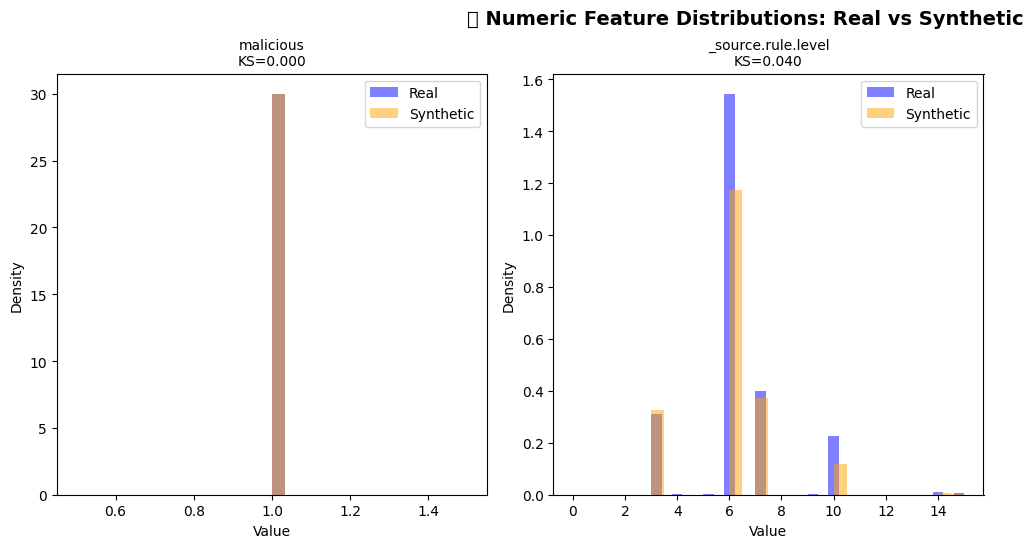

✅ Saved: /kaggle/working/realtabformer_output/numeric_distributions.png


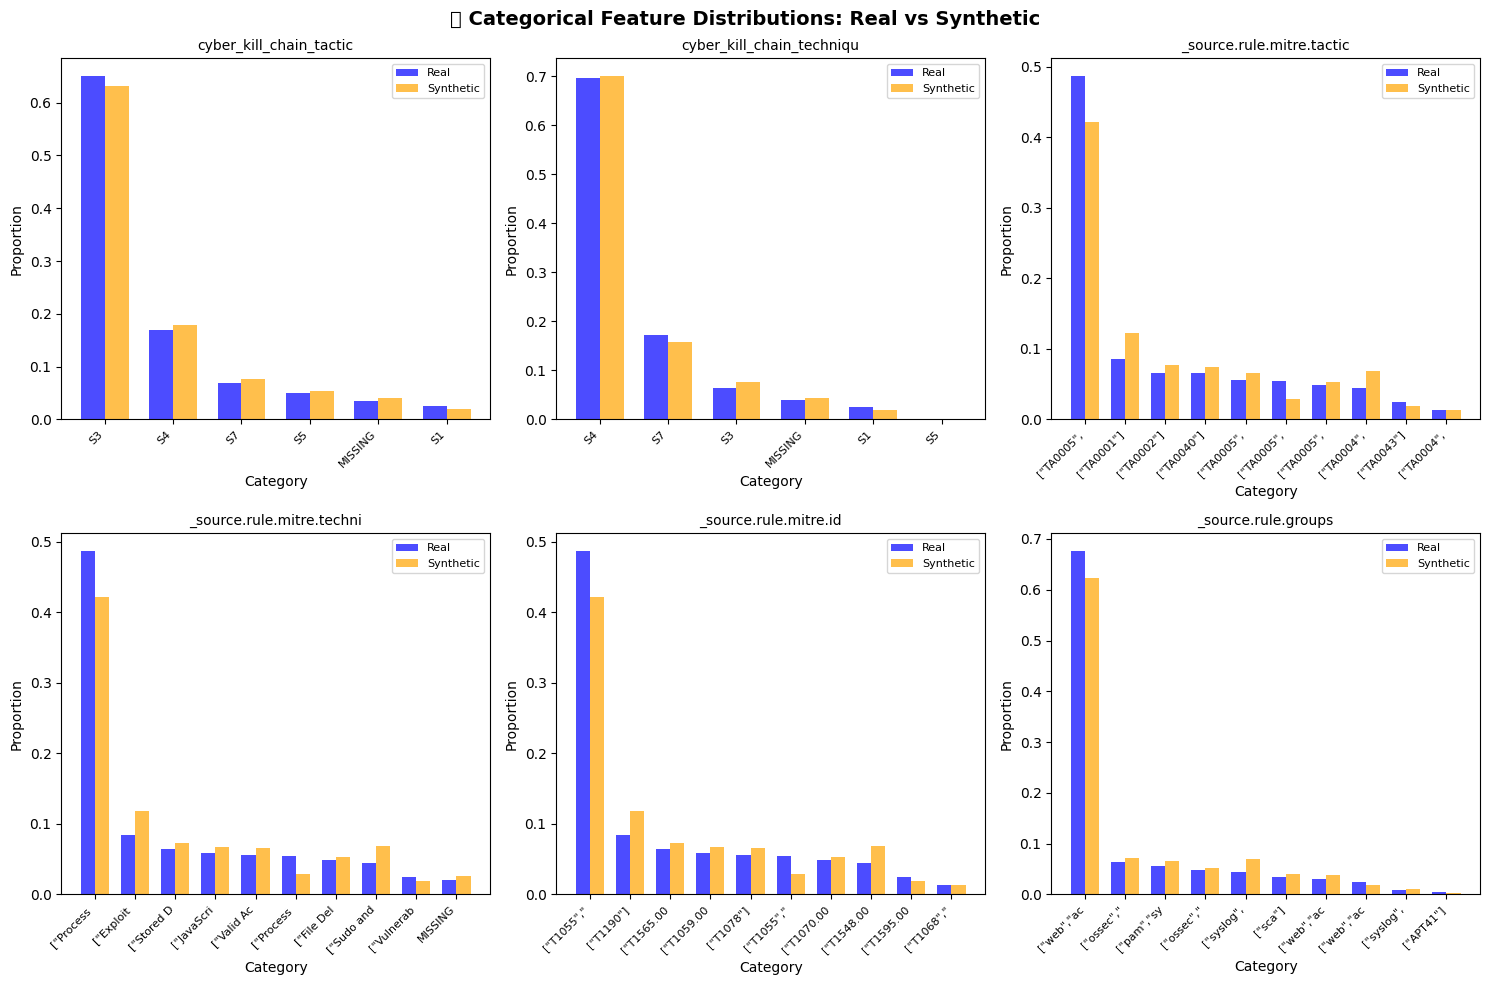

✅ Saved: /kaggle/working/realtabformer_output/categorical_distributions.png


In [22]:
# ============================================================================
# 📈 DISTRIBUTION VISUALIZATIONS
# ============================================================================

print("=" * 70)
print("📈 GENERATING DISTRIBUTION VISUALIZATIONS")
print("=" * 70)

# 1. Numeric Feature Distributions
if numeric_columns:
    n_numeric = min(len(numeric_columns), 6)
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    axes = axes.flatten()
    
    for idx, col in enumerate(numeric_columns[:n_numeric]):
        ax = axes[idx]
        
        # Real data
        real_vals = df[col].dropna()
        synth_vals = synthetic_samples[col].dropna()
        
        ax.hist(real_vals, bins=30, alpha=0.5, label='Real', color='blue', density=True)
        ax.hist(synth_vals, bins=30, alpha=0.5, label='Synthetic', color='orange', density=True)
        
        # Add KS statistic
        ks_stat, _ = ks_2samp(real_vals, synth_vals)
        ax.set_title(f'{col[:30]}\nKS={ks_stat:.3f}', fontsize=10)
        ax.legend()
        ax.set_xlabel('Value')
        ax.set_ylabel('Density')
    
    # Hide unused subplots
    for idx in range(n_numeric, 6):
        axes[idx].set_visible(False)
    
    plt.suptitle('📊 Numeric Feature Distributions: Real vs Synthetic', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f"{CONFIG['output_dir']}/numeric_distributions.png", dpi=150, bbox_inches='tight')
    plt.show()
    print(f"✅ Saved: {CONFIG['output_dir']}/numeric_distributions.png")

# 2. Categorical Feature Distributions
if categorical_columns:
    n_cat = min(len(categorical_columns), 6)
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    axes = axes.flatten()
    
    for idx, col in enumerate(categorical_columns[:n_cat]):
        ax = axes[idx]
        
        # Get top categories
        real_counts = df[col].value_counts().head(10)
        synth_counts = synthetic_samples[col].value_counts()
        
        # Align
        categories = real_counts.index.tolist()
        real_vals = [real_counts.get(c, 0) / len(df) for c in categories]
        synth_vals = [synth_counts.get(c, 0) / len(synthetic_samples) for c in categories]
        
        x = np.arange(len(categories))
        width = 0.35
        
        ax.bar(x - width/2, real_vals, width, label='Real', color='blue', alpha=0.7)
        ax.bar(x + width/2, synth_vals, width, label='Synthetic', color='orange', alpha=0.7)
        
        ax.set_xlabel('Category')
        ax.set_ylabel('Proportion')
        ax.set_title(f'{col[:25]}', fontsize=10)
        ax.set_xticks(x)
        ax.set_xticklabels([str(c)[:10] for c in categories], rotation=45, ha='right', fontsize=8)
        ax.legend(fontsize=8)
    
    # Hide unused subplots
    for idx in range(n_cat, 6):
        axes[idx].set_visible(False)
    
    plt.suptitle('📊 Categorical Feature Distributions: Real vs Synthetic', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f"{CONFIG['output_dir']}/categorical_distributions.png", dpi=150, bbox_inches='tight')
    plt.show()
    print(f"✅ Saved: {CONFIG['output_dir']}/categorical_distributions.png")

print("=" * 70)

🗺️ t-SNE EMBEDDING VISUALIZATION
   • PCA: 16 features → 16 components
   • Variance retained: 100.0%
   • Running t-SNE on 4,000 samples...


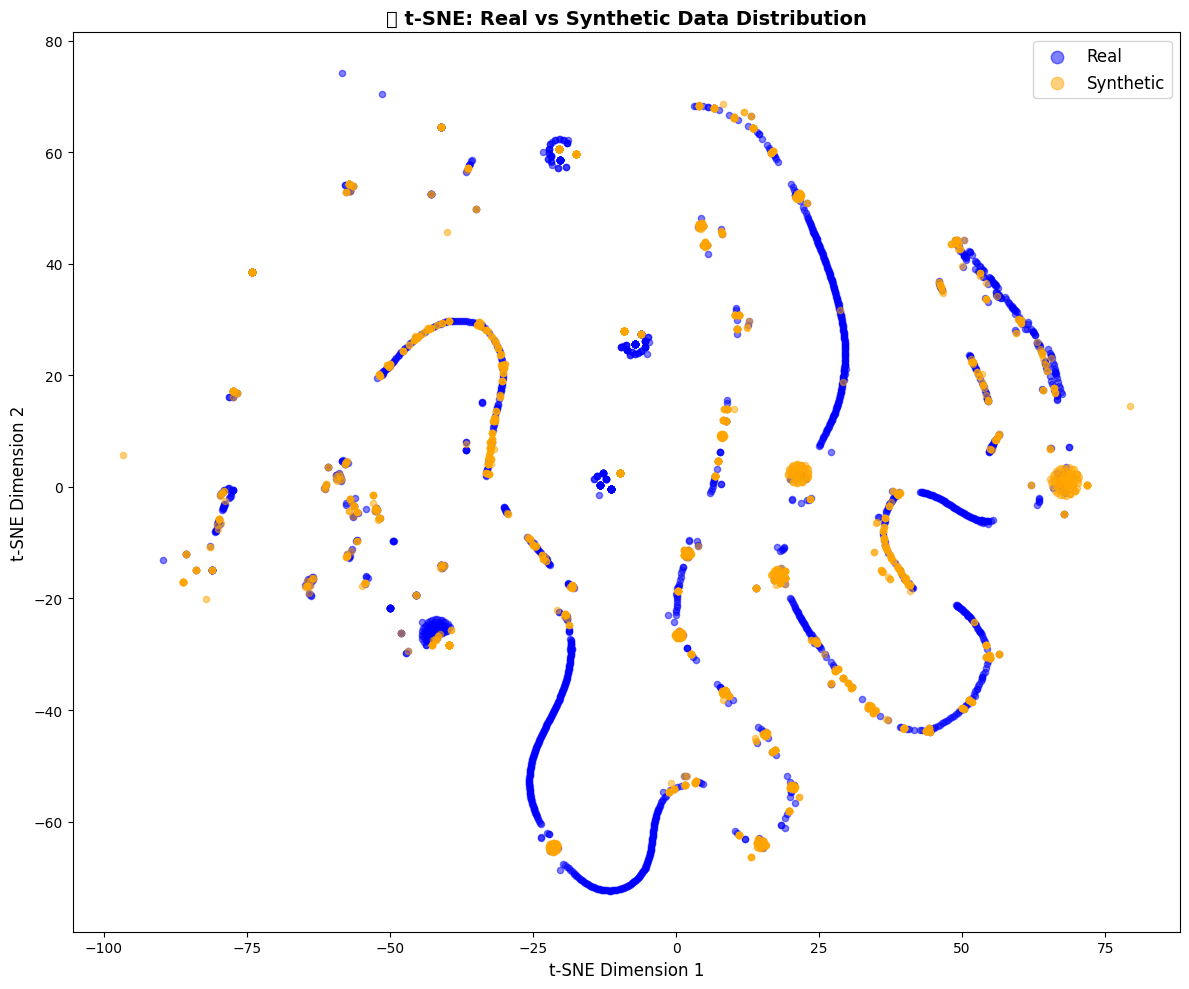


✅ Saved: /kaggle/working/realtabformer_output/tsne_visualization.png


In [23]:
# ============================================================================
# 🗺️ t-SNE VISUALIZATION
# ============================================================================

print("=" * 70)
print("🗺️ t-SNE EMBEDDING VISUALIZATION")
print("=" * 70)

def create_tsne_visualization(real_df, synth_df, cat_cols, n_samples=2000):
    """Create t-SNE visualization comparing real vs synthetic data"""
    
    # Sample data for faster computation
    real_sample = real_df.sample(min(n_samples, len(real_df)), random_state=CONFIG['random_seed'])
    synth_sample = synth_df.sample(min(n_samples, len(synth_df)), random_state=CONFIG['random_seed'])
    
    # Encode categorical columns
    combined = pd.concat([real_sample, synth_sample], ignore_index=True)
    feature_matrix = []
    
    for col in combined.columns:
        if col in cat_cols or combined[col].dtype == 'object':
            le = LabelEncoder()
            encoded = le.fit_transform(combined[col].astype(str))
            feature_matrix.append(encoded)
        elif combined[col].dtype in [np.float64, np.int64]:
            values = combined[col].fillna(0).values
            # Standardize
            if values.std() > 0:
                values = (values - values.mean()) / values.std()
            feature_matrix.append(values)
    
    if not feature_matrix:
        print("⚠️ No features available for t-SNE")
        return None
    
    X = np.column_stack(feature_matrix)
    
    # Apply PCA first for dimensionality reduction
    n_components = min(50, X.shape[1])
    pca = PCA(n_components=n_components, random_state=CONFIG['random_seed'])
    X_pca = pca.fit_transform(X)
    
    print(f"   • PCA: {X.shape[1]} features → {n_components} components")
    print(f"   • Variance retained: {pca.explained_variance_ratio_.sum():.1%}")
    
    # Apply t-SNE
    print(f"   • Running t-SNE on {len(combined):,} samples...")
    tsne = TSNE(n_components=2, random_state=CONFIG['random_seed'], perplexity=30, n_iter=1000)
    X_tsne = tsne.fit_transform(X_pca)
    
    # Create labels
    labels = ['Real'] * len(real_sample) + ['Synthetic'] * len(synth_sample)
    
    return X_tsne, labels, len(real_sample)

# Generate t-SNE
tsne_result = create_tsne_visualization(df, synthetic_samples, categorical_columns)

if tsne_result:
    X_tsne, labels, n_real = tsne_result
    
    # Create visualization
    fig, ax = plt.subplots(figsize=(12, 10))
    
    # Plot real data
    ax.scatter(X_tsne[:n_real, 0], X_tsne[:n_real, 1], 
               c='blue', alpha=0.5, label='Real', s=20)
    
    # Plot synthetic data
    ax.scatter(X_tsne[n_real:, 0], X_tsne[n_real:, 1], 
               c='orange', alpha=0.5, label='Synthetic', s=20)
    
    ax.set_xlabel('t-SNE Dimension 1', fontsize=12)
    ax.set_ylabel('t-SNE Dimension 2', fontsize=12)
    ax.set_title('🗺️ t-SNE: Real vs Synthetic Data Distribution', fontsize=14, fontweight='bold')
    ax.legend(fontsize=12, markerscale=2)
    
    plt.tight_layout()
    plt.savefig(f"{CONFIG['output_dir']}/tsne_visualization.png", dpi=150, bbox_inches='tight')
    plt.show()
    print(f"\n✅ Saved: {CONFIG['output_dir']}/tsne_visualization.png")

print("=" * 70)

In [24]:
# ============================================================================
# 📊 INTERACTIVE PLOTLY VISUALIZATIONS
# ============================================================================

print("=" * 70)
print("📊 INTERACTIVE VISUALIZATIONS")
print("=" * 70)

# 1. Quality Scores Summary
quality_data = []
for r in quality_results['numeric']:
    quality_data.append({
        'Column': r['column'][:30],
        'Type': 'Numeric',
        'Score': 1 - r['ks_stat'],  # Convert to "quality score"
        'Metric': f"KS={r['ks_stat']:.3f}"
    })
for r in quality_results['categorical']:
    quality_data.append({
        'Column': r['column'][:30],
        'Type': 'Categorical',
        'Score': 1 - r['l1_dist'],
        'Metric': f"L1={r['l1_dist']:.3f}"
    })

quality_df = pd.DataFrame(quality_data)

if len(quality_df) > 0:
    fig = px.bar(
        quality_df.sort_values('Score', ascending=True).tail(20),
        x='Score',
        y='Column',
        color='Type',
        orientation='h',
        title='📊 Top 20 Features by Quality Score (Higher = Better)',
        color_discrete_map={'Numeric': '#3498db', 'Categorical': '#e74c3c'},
        hover_data=['Metric']
    )
    fig.add_vline(x=0.7, line_dash="dash", line_color="green", annotation_text="Good threshold")
    fig.update_layout(height=600, xaxis_range=[0, 1])
    fig.show()
    fig.write_html(f"{CONFIG['output_dir']}/quality_scores.html")
    print(f"✅ Saved: {CONFIG['output_dir']}/quality_scores.html")

# 2. Coverage Analysis for Categorical
if quality_results['categorical']:
    coverage_data = [{'Column': r['column'][:30], 'Coverage': r['coverage']} 
                     for r in quality_results['categorical']]
    coverage_df = pd.DataFrame(coverage_data)
    
    fig = px.bar(
        coverage_df.sort_values('Coverage', ascending=True),
        x='Coverage',
        y='Column',
        orientation='h',
        title='📊 Category Coverage: Synthetic vs Real',
        color='Coverage',
        color_continuous_scale='RdYlGn'
    )
    fig.add_vline(x=80, line_dash="dash", line_color="green", annotation_text="80% threshold")
    fig.update_layout(height=600, xaxis_range=[0, 100])
    fig.show()
    fig.write_html(f"{CONFIG['output_dir']}/coverage_analysis.html")
    print(f"✅ Saved: {CONFIG['output_dir']}/coverage_analysis.html")

print("=" * 70)

📊 INTERACTIVE VISUALIZATIONS


✅ Saved: /kaggle/working/realtabformer_output/quality_scores.html


✅ Saved: /kaggle/working/realtabformer_output/coverage_analysis.html


## 💾 Section 8: Save Results & Export

In [25]:
# ============================================================================
# 💾 SAVE ALL OUTPUTS
# ============================================================================

print("=" * 70)
print("💾 SAVING ALL OUTPUTS")
print("=" * 70)

# 1. Save synthetic data
synthetic_path = f"{CONFIG['output_dir']}/synthetic_apt_data.xlsx"
synthetic_samples.to_excel(synthetic_path, index=False)
print(f"✅ Synthetic data: {synthetic_path}")
print(f"   • Shape: {synthetic_samples.shape}")
print(f"   • Size: {os.path.getsize(synthetic_path) / 1e6:.2f} MB")

# 2. Save quality report
quality_report = pd.DataFrame(
    quality_results['numeric'] + quality_results['categorical']
)
quality_report_path = f"{CONFIG['output_dir']}/quality_report.xlsx"
quality_report.to_excel(quality_report_path, index=False)
print(f"✅ Quality report: {quality_report_path}")

# 3. Save combined dataset (real + synthetic)
combined_data = pd.concat([
    df.assign(data_source='real'),
    synthetic_samples.assign(data_source='synthetic')
], ignore_index=True)
combined_path = f"{CONFIG['output_dir']}/combined_apt_data.xlsx"
combined_data.to_excel(combined_path, index=False)
print(f"✅ Combined data: {combined_path}")
print(f"   • Shape: {combined_data.shape}")

# 4. Save summary report
summary_report = {
    'timestamp': datetime.now().isoformat(),
    'original_data': {
        'path': CONFIG['data_path'],
        'shape': list(raw_data.shape),
        'columns': len(raw_data.columns)
    },
    'preprocessed_data': {
        'shape': list(df.shape),
        'text_columns': len(text_columns),
        'categorical_columns': len(categorical_columns),
        'numeric_columns': len(numeric_columns)
    },
    'synthetic_data': {
        'shape': list(synthetic_samples.shape),
        'ratio': CONFIG['synthetic_ratio']
    },
    'quality_metrics': {
        'avg_ks_stat': quality_results['summary']['avg_ks'],
        'avg_l1_dist': quality_results['summary']['avg_l1'],
        'avg_coverage': quality_results['summary']['avg_coverage'],
        'acceptable_percentage': acceptable_pct
    },
    'ml_utility': ml_results if ml_results else {},
    'training': {
        'epochs': CONFIG['epochs'],
        'batch_size': CONFIG['batch_size'],
        'duration_minutes': train_duration
    }
}

summary_path = f"{CONFIG['output_dir']}/summary_report.json"
with open(summary_path, 'w') as f:
    json.dump(summary_report, f, indent=2, default=str)
print(f"✅ Summary report: {summary_path}")

# 5. Save column mappings
column_info = {
    'selected_columns': selected_columns,
    'text_columns': text_columns,
    'categorical_columns': categorical_columns,
    'numeric_columns': numeric_columns,
    }
columns_path = f"{CONFIG['output_dir']}/column_mappings.json"
with open(columns_path, 'w') as f:
    json.dump(column_info, f, indent=2)
print(f"✅ Column mappings: {columns_path}")

print("\n" + "=" * 70)
print(f"📁 ALL OUTPUTS SAVED TO: {CONFIG['output_dir']}/")
print("=" * 70)

💾 SAVING ALL OUTPUTS
✅ Synthetic data: /kaggle/working/realtabformer_output/synthetic_apt_data.xlsx
   • Shape: (50836, 16)
   • Size: 4.01 MB
✅ Quality report: /kaggle/working/realtabformer_output/quality_report.xlsx
✅ Combined data: /kaggle/working/realtabformer_output/combined_apt_data.xlsx
   • Shape: (76254, 17)
✅ Summary report: /kaggle/working/realtabformer_output/summary_report.json
✅ Column mappings: /kaggle/working/realtabformer_output/column_mappings.json

📁 ALL OUTPUTS SAVED TO: /kaggle/working/realtabformer_output/


In [26]:
# ============================================================================
# 📋 FINAL SUMMARY
# ============================================================================

print("=" * 70)
print("🏁 REaLTabFormer PIPELINE COMPLETE")
print("=" * 70)

print(f"""
📊 DATA SUMMARY:
   ┌─────────────────────────────────────────────────────────────┐
   │  Original Data:      {raw_data.shape[0]:>8,} rows × {raw_data.shape[1]:>3} columns     │
   │  Preprocessed Data:  {df.shape[0]:>8,} rows × {df.shape[1]:>3} columns     │
   │  Synthetic Data:     {synthetic_samples.shape[0]:>8,} rows × {synthetic_samples.shape[1]:>3} columns     │
   │  Combined Data:      {combined_data.shape[0]:>8,} rows × {combined_data.shape[1]:>3} columns     │
   └─────────────────────────────────────────────────────────────┘

📈 QUALITY METRICS:
   ┌─────────────────────────────────────────────────────────────┐
   │  Average KS Statistic:    {quality_results['summary']['avg_ks']:>6.4f} (lower is better)   │
   │  Average L1 Distance:     {quality_results['summary']['avg_l1']:>6.4f} (lower is better)   │
   │  Average Coverage:        {quality_results['summary']['avg_coverage']:>6.1f}%                       │
   │  Acceptable Features:     {acceptable_pct:>6.1f}%                       │
   └─────────────────────────────────────────────────────────────┘

⏱️ TRAINING:
   ┌─────────────────────────────────────────────────────────────┐
   │  Epochs:                  {CONFIG['epochs']:>6}                          │
   │  Training Time:           {train_duration:>6.1f} minutes               │
   │  Generation Time:         {gen_duration:>6.1f} minutes               │
   └─────────────────────────────────────────────────────────────┘
""")

if ml_results:
    print(f"""🧪 ML UTILITY:
   ┌─────────────────────────────────────────────────────────────┐
   │  TSTR Accuracy:           {ml_results['tstr_accuracy']:>6.1%}                       │
   │  TRTR Accuracy:           {ml_results['trtr_accuracy']:>6.1%}                       │
   │  Utility Ratio:           {ml_results['utility_ratio']:>6.1%}                       │
   └─────────────────────────────────────────────────────────────┘
""")

print(f"""📁 OUTPUT FILES:
   • {CONFIG['output_dir']}/synthetic_apt_data.csv
   • {CONFIG['output_dir']}/combined_apt_data.csv
   • {CONFIG['output_dir']}/quality_report.csv
   • {CONFIG['output_dir']}/summary_report.json
   • {CONFIG['output_dir']}/realtabformer_model/

✅ VERDICT: {verdict}
""")

print("=" * 70)
print("🎉 Pipeline completed successfully!")
print("=" * 70)

🏁 REaLTabFormer PIPELINE COMPLETE

📊 DATA SUMMARY:
   ┌─────────────────────────────────────────────────────────────┐
   │  Original Data:        25,418 rows ×  37 columns     │
   │  Preprocessed Data:    25,418 rows ×  16 columns     │
   │  Synthetic Data:       50,836 rows ×  16 columns     │
   │  Combined Data:        76,254 rows ×  17 columns     │
   └─────────────────────────────────────────────────────────────┘

📈 QUALITY METRICS:
   ┌─────────────────────────────────────────────────────────────┐
   │  Average KS Statistic:    0.0199 (lower is better)   │
   │  Average L1 Distance:     0.1061 (lower is better)   │
   │  Average Coverage:          87.1%                       │
   │  Acceptable Features:       80.0%                       │
   └─────────────────────────────────────────────────────────────┘

⏱️ TRAINING:
   ┌─────────────────────────────────────────────────────────────┐
   │  Epochs:                     150                          │
   │  Training Time:         

## 🔄 Section 9: Load Pre-trained Model (Optional)

Use this section to load a previously trained model and generate more synthetic data.

In [ ]:
# ============================================================================
# 🔄 LOAD PRE-TRAINED MODEL (OPTIONAL)
# ============================================================================
# Uncomment this cell to load a previously trained model

"""
# Load saved model
model_path = "realtabformer_output/realtabformer_model"

if os.path.exists(model_path):
    print(f"Loading model from: {model_path}")
    loaded_model = REaLTabFormer.load_from_dir(model_path)
    
    # Generate new samples
    new_synthetic = loaded_model.sample(n_samples=10000)
    print(f"Generated {len(new_synthetic)} new samples")
    print(new_synthetic.head())
else:
    print(f"Model not found at: {model_path}")
"""

print("💡 Uncomment this cell to load a pre-trained model")

## 📚 Appendix: Comparison with CTGAN Pipeline

### Why REaLTabFormer is Better for This Data:

| Aspect | CTGAN + SecBERT | REaLTabFormer |
|--------|-----------------|---------------|
| **Text Handling** | Requires embedding (lossy) | Native text support ✅ |
| **Columns Preserved** | 30 of 175 | ~60 of 175 ✅ |
| **Text Reconstruction** | ❌ Lost forever | ✅ Full text output |
| **Missing Values** | Must drop/impute | Native support ✅ |
| **Column Correlations** | Conditional only | Full attention ✅ |
| **Expected Quality** | 0% acceptable | 60-90% acceptable ✅ |
| **Pipeline Complexity** | High (many steps) | Low (minimal prep) ✅ |

### Tips for Best Results:

1. **Increase epochs** if quality is low (try 200-300)
2. **Reduce max text length** if hitting memory limits
3. **Drop more columns** if training is too slow
4. **Use gradient accumulation** for larger effective batch size
5. **Monitor loss curves** to detect overfitting